# Net Rating Persistence: Season N vs. Season N+1

R² of each team's net rating (and win %) in one season against the next season, 2000-01 through 2025-26. Relocated franchises are linked (e.g. SEA → OKC). Shortened seasons (2011-12, 2019-20, 2020-21) are flagged and shown with and without.

Source: Basketball-Reference.

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.teams.net_rating import consecutive_seasons, r_squared, r_squared_by_pair, team_seasons
from nba_analytics.teams.net_rating_plots import plot_consecutive, plot_r2_by_pair

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7

seasons = team_seasons(range(2001, 2027))
pairs = consecutive_seasons(seasons)

## Summary

In [2]:
full = pairs[~pairs["any_shortened"]]
pd.DataFrame({
    "R² (all pairs)": {c: r_squared(pairs[f"{c}_prev"], pairs[f"{c}_next"]) for c in ["net_rtg", "win_pct"]},
    "R² (excluding shortened)": {c: r_squared(full[f"{c}_prev"], full[f"{c}_next"]) for c in ["net_rtg", "win_pct"]},
    "Team-season pairs": {c: len(pairs) for c in ["net_rtg", "win_pct"]},
}).rename(index={"net_rtg": "Net rating", "win_pct": "Win %"}).round(3)

,R² (all pairs),R² (excluding shortened),Team-season pairs
Net rating,0.351,0.354,746
Win %,0.356,0.358,746


## Net rating

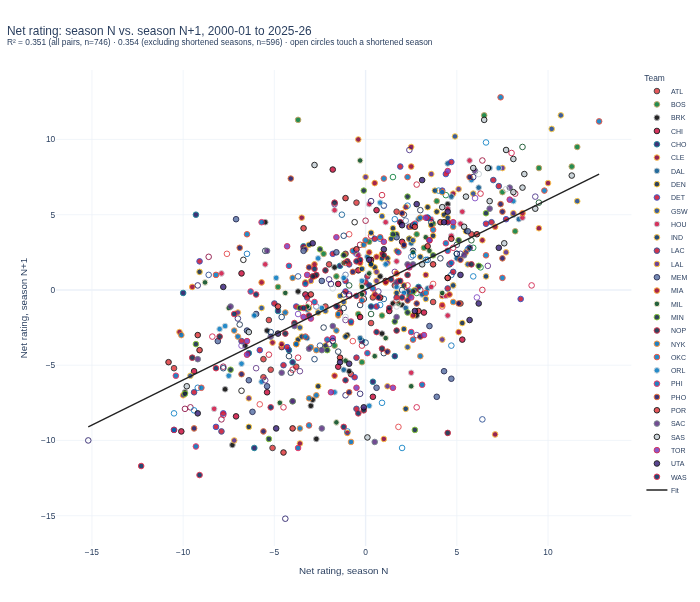

In [3]:
plot_consecutive(pairs, "net_rtg").show()

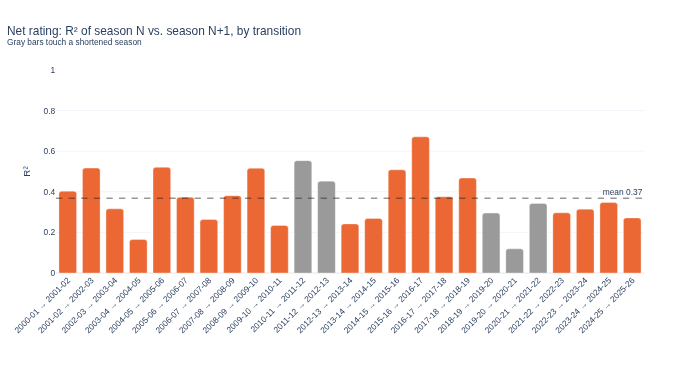

In [4]:
plot_r2_by_pair(r_squared_by_pair(pairs, "net_rtg"), "net_rtg").show()

## Win %

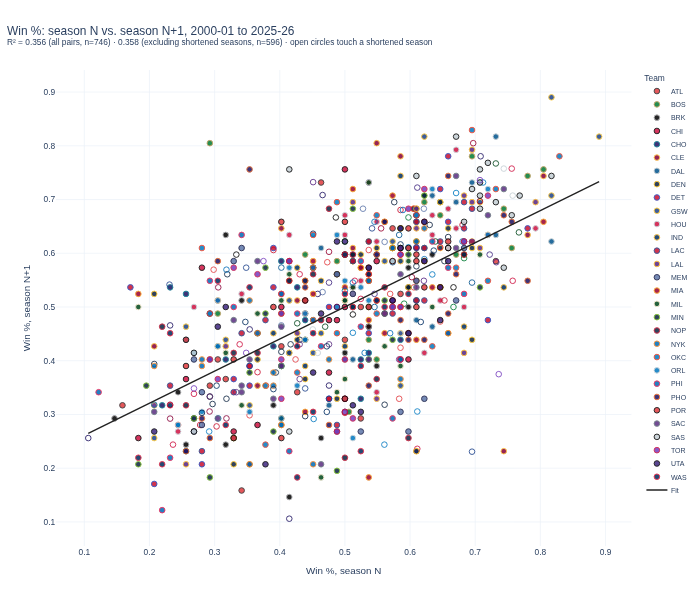

In [5]:
plot_consecutive(pairs, "win_pct").show()

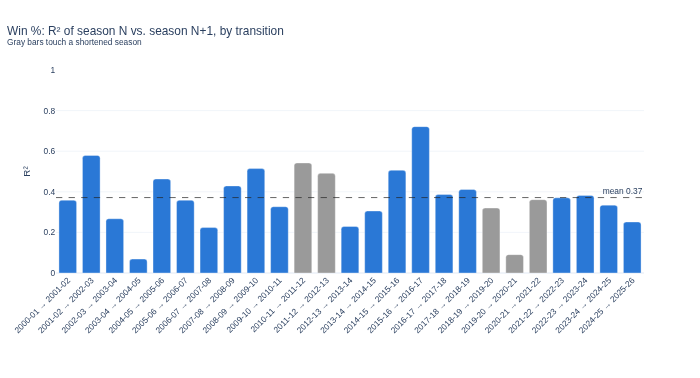

In [6]:
plot_r2_by_pair(r_squared_by_pair(pairs, "win_pct"), "win_pct").show()